# 🫁 Phase 3: Triple Fusion (Image + Text + Clinical Metadata)
## Experiments 5 & 6 — Clean Patient-Level Split & Clinical Refinement
### PneumoFusionNet | MIMIC-CXR PA Viewpoint (3,763 radiographs)

This notebook implements **Phase 3 Triple Fusion** and the **4-Way Multimodal Ablation** with all professor requirements:
1. **Experiment 1 (Patient Split)**: Canonical stratified 70/15/15 split by `subject_id` (zero patient leakage, shared across all phases).
2. **Experiment 2 (Checkpoint Overlap)**: Image encoder uses `densenet121-res224-nih` from Phase 1 (`phase1_best_model.pth`, zero MIMIC pretraining overlap).
3. **Experiment 4 (Multimodal & Text Masking)**: Text encoder uses fine-tuned ClinicalBERT from Phase 2 (`best_phase2_model.pth`). BERT padding mask passed to cross-attention as `key_padding_mask`.
4. **Experiment 4 Preprocessing**: INDICATION + FINDINGS sections only; raw-report fallback (`text[:512]`) completely removed; empty reports masked.
5. **Experiment 6 (Clinical Refinement)**: Removed `is_deceased` from features. 16 clinical features standardized and imputed with median strictly on training partition only.
6. **Experiment 5 (4-Way Comparison)**: Evaluates Configuration A (CXR), B (CXR+Text), C (CXR+WBC), D (CXR+Text+WBC), and Full (CXR+Text+16 Clinical Feats).
7. **Validation-Derived Threshold**: Optimal threshold selected purely on validation data and applied frozen to test set.


In [1]:
# --- CELL 0: Imports & Reproducibility ---
import os, random, warnings, json, copy, re
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import cv2
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from transformers import AutoTokenizer, AutoModel
import torchxrayvision as xrv

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, accuracy_score, f1_score
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
print(f'PyTorch: {torch.__version__}')

Device : cuda
PyTorch: 2.5.1+cu121


In [2]:
# --- CELL 1: Configuration & Paths (Experiment 1 — Triple Fusion) ---
DATASET_DIR  = r'C:\2026\PneumoFusionNet\mimic\main\dataset'
MAIN_DIR     = r'C:\2026\PneumoFusionNet\mimic\main'

# Input data
PAIRED_CSV   = os.path.join(DATASET_DIR, 'phase3_paired_scaleup_final.csv')
SPLIT_CSV    = os.path.join(DATASET_DIR, 'patient_split.csv')
BBOX_CSV     = os.path.join(MAIN_DIR, 'outputs', 'Phase_1.1v4_PA_crossval_scaleup', 'lung_bboxes.csv')

# Checkpoints from Experiment 2/3 (NIH clean weights) and Experiment 4 (multimodal)
P1_CKPT      = os.path.join(MAIN_DIR, 'outputs', 'Phase_1_NIH_single_split_exp2', 'phase1_best_model.pth')
P2V2_CKPT    = os.path.join(MAIN_DIR, 'outputs', 'Phase_2_NIH_single_split_exp2', 'best_phase2_model.pth')

P1_RES       = os.path.join(MAIN_DIR, 'outputs', 'Phase_1_NIH_single_split_exp2', 'phase1_results.json')
P2_RES       = os.path.join(MAIN_DIR, 'outputs', 'Phase_2_NIH_single_split_exp2', 'phase2_results.json')

# Output directory for Phase 3 (Experiments 5 & 6)
SAVE_DIR     = os.path.join(MAIN_DIR, 'outputs', 'Phase_3_NIH_single_split_exp5_6')
os.makedirs(SAVE_DIR, exist_ok=True)

# Model architecture hyperparameters
IMG_SIZE       = 224
MAX_TEXT_LEN   = 256
CLINBERT_MODEL = 'emilyalsentzer/Bio_ClinicalBERT'
IMG_FEAT_DIM   = 1024
TXT_FEAT_DIM   = 768
ATTN_DIM       = 512
ATTN_HEADS     = 8
META_HIDDEN    = 128
META_OUT_DIM   = 64
N_CLINICAL_FEATURES = 16

# Training hyperparameters
BATCH_SIZE  = 16
LR_FUSION   = 2e-4
LR_BERT     = 1e-5
LR_META     = 1e-3
EPOCHS      = 30
PATIENCE    = 8
FOCAL_GAMMA = 2.0
MIXUP_ALPHA = 0.2
CLASSES     = ['NORMAL', 'PNEUMONIA']
MEAN = [0.5020]; STD = [0.2703]

CLINICAL_FEATURES = [
    'age', 'gender_M',
    'heart_rate', 'respiratory_rate', 'spo2', 'systolic_bp', 'diastolic_bp', 'temperature_f',
    'wbc', 'hemoglobin', 'hematocrit', 'creatinine', 'crp', 'alk_phos', 'albumin',
    'has_vitals'
]

IMG_BASE = DATASET_DIR

print(f'Paired CSV    : {os.path.exists(PAIRED_CSV)} -> {PAIRED_CSV}')
print(f'Split CSV     : {os.path.exists(SPLIT_CSV)} -> {SPLIT_CSV}')
print(f'BBox CSV      : {os.path.exists(BBOX_CSV)}')
print(f'P1 checkpoint : {os.path.exists(P1_CKPT)} (Exp 2/3 NIH Phase 1 model)')
print(f'P2v2 ckpt     : {os.path.exists(P2V2_CKPT)} (Exp 4 multimodal model)')
print(f'Save dir      : {SAVE_DIR}')
print(f'Clinical feats: {N_CLINICAL_FEATURES}')

Paired CSV    : True -> C:\2026\PneumoFusionNet\mimic\main\dataset\phase3_paired_scaleup_final.csv
Split CSV     : True -> C:\2026\PneumoFusionNet\mimic\main\dataset\patient_split.csv
BBox CSV      : True
P1 checkpoint : True (Exp 2/3 NIH Phase 1 model)
P2v2 ckpt     : True (Exp 4 multimodal model)
Save dir      : C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_3_NIH_single_split_exp5_6
Clinical feats: 16


In [3]:
# --- CELL 2: Data Loading (SCALEUP - single merged CSV) ---
import re

def resolve_path(p):
    if pd.isna(p) or str(p).strip() == '': return ''
    p = str(p).replace('/', os.sep).replace('\\\\', os.sep)
    return p if os.path.isabs(p) else os.path.join(IMG_BASE, p)

# Load the single merged CSV (text + clinical already combined)
df_raw = pd.read_csv(PAIRED_CSV)
df_raw['image_path']  = df_raw['image_path'].apply(resolve_path)
df_raw['report_path'] = df_raw['report_path'].apply(resolve_path)

# Merge indication & findings from Phase 2 paired dataset for 100% exact parity with Exp 4
P2_PAIRED_CSV = os.path.join(DATASET_DIR, 'mimic_paired_dataset_phase2.csv')
if os.path.exists(P2_PAIRED_CSV):
    p2_meta = pd.read_csv(P2_PAIRED_CSV)[['dicom_id', 'indication', 'findings']]
    df_raw = df_raw.merge(p2_meta, on='dicom_id', how='left')
    print(f'Merged indication & findings from Phase 2 dataset: {len(df_raw)} rows')

print(f'Loaded {len(df_raw):,} rows | Labels: {df_raw["label"].value_counts().to_dict()}')
print(f'Clinical columns present: {[c for c in CLINICAL_FEATURES if c in df_raw.columns]}')
print(f'Missing clinical: {[c for c in CLINICAL_FEATURES if c not in df_raw.columns]}')


Merged indication & findings from Phase 2 dataset: 3763 rows
Loaded 3,763 rows | Labels: {1: 1891, 0: 1872}
Clinical columns present: ['age', 'gender_M', 'heart_rate', 'respiratory_rate', 'spo2', 'systolic_bp', 'diastolic_bp', 'temperature_f', 'wbc', 'hemoglobin', 'hematocrit', 'creatinine', 'crp', 'alk_phos', 'albumin', 'has_vitals']
Missing clinical: []


In [4]:
# --- CELL 3: Text Preparation (FINDINGS + INDICATION, leakage redaction) ---
# Experiment 4 & 5 requirement: Remove raw-report fallback, use ONLY intended sections,
# record empty reports count, and do not silently replace missing text.

text_df = df_raw.copy()

LEAKAGE_RE = re.compile(
    r'\bpneumonia\b|\bpneumonic\b|\bno[ -]acute[ -]\w+|\bno finding\w*'
    r'|\bcompatible with\b|\bconsistent with\b|\bnormal study\b|\bno significant\b',
    re.IGNORECASE
)

def build_report_text(row):
    parts = []
    ind = str(row.get('indication', '')).strip()
    if ind and ind.lower() != 'nan' and len(ind) > 3:
        parts.append(ind)
    find = str(row.get('findings', '')).strip()
    if find and find.lower() != 'nan' and len(find) > 3:
        parts.append(find)
    # STRICT: NO FALLBACK to raw_report (Teacher requirement)
    result = ' '.join(parts).strip()
    result = LEAKAGE_RE.sub('[REDACTED]', result)
    return result

text_df['report_rich'] = text_df.apply(build_report_text, axis=1)

# Record and report empty reports after section extraction
n_total = len(text_df)
n_empty = (text_df['report_rich'].str.strip() == '').sum()
pct_empty = (n_empty / n_total) * 100

print('=' * 70)
print('REPORT SECTION EXTRACTION SUMMARY (Experiment 4 Compliance)')
print('=' * 70)
print(f'  Total cohort size                        : {n_total}')
print(f'  Reports with valid FINDINGS/INDICATION  : {n_total - n_empty} ({100 - pct_empty:.2f}%)')
print(f'  Reports EMPTY after section extraction   : {n_empty} ({pct_empty:.2f}%)')
print(f'  Raw-report fallback                      : REMOVED (No silent replacement)')
print(f'  Avg words in non-empty reports          : {text_df[text_df["report_rich"]!=""]["report_rich"].str.split().str.len().mean():.1f}')
print('=' * 70)


REPORT SECTION EXTRACTION SUMMARY (Experiment 4 Compliance)
  Total cohort size                        : 3763
  Reports with valid FINDINGS/INDICATION  : 3545 (94.21%)
  Reports EMPTY after section extraction   : 218 (5.79%)
  Raw-report fallback                      : REMOVED (No silent replacement)
  Avg words in non-empty reports          : 50.0


In [5]:
# --- CELL 4: Clinical Feature & WBC Availability Reporting (Exp 5 & 6) ---
df = text_df.copy()

print(f'Rows            : {len(df):,}')
print(f'Label distribution: {df["label"].value_counts().rename({0: "Normal", 1: "Pneumonia"}).to_dict()}')

# Verify report_rich is present
assert 'report_rich' in df.columns, 'report_rich missing — re-run Cell 3'

# Experiment 6: Confirm is_deceased is excluded
assert 'is_deceased' not in CLINICAL_FEATURES, 'is_deceased must NOT be in CLINICAL_FEATURES (Exp 6 requirement)'

CLINICAL_FEATURES_USED = [c for c in CLINICAL_FEATURES if c in df.columns]
N_CLINICAL_FEATURES = len(CLINICAL_FEATURES_USED)
print(f'\nUsing {N_CLINICAL_FEATURES} clinical features (is_deceased removed):')
print(f'  {CLINICAL_FEATURES_USED}')

# --- Experiment 5: Detailed WBC Availability & Missingness Report ---
n_wbc_avail = df['wbc'].notna().sum()
pct_wbc_avail = (n_wbc_avail / len(df)) * 100
n_wbc_miss = df['wbc'].isna().sum()
pct_wbc_miss = (n_wbc_miss / len(df)) * 100

print('\n' + '=' * 70)
print('EXPERIMENT 5: WBC BIOMARKER AVAILABILITY & MISSINGNESS')
print('=' * 70)
print(f'  Valid WBC available           : {n_wbc_avail:,} / {len(df):,} ({pct_wbc_avail:.1f}%)')
print(f'  Missing WBC (imputed on train): {n_wbc_miss:,} / {len(df):,} ({pct_wbc_miss:.1f}%)')
print('  Note: Retrospective +-2-day clinical lab matching (exploratory analysis).')
print('=' * 70)

print(f'\nMissingness across all {N_CLINICAL_FEATURES} features (will be imputed with train median in Cell 5):')
for col in CLINICAL_FEATURES_USED:
    n = df[col].isna().sum()
    bar = '#' * int((100 - 100*n/len(df)) / 5)
    print(f'  {col:20s}: {n:4d} missing ({100*n/len(df):.1f}%) | Present: {100-100*n/len(df):.1f}% {bar}')


Rows            : 3,763
Label distribution: {'Pneumonia': 1891, 'Normal': 1872}

Using 16 clinical features (is_deceased removed):
  ['age', 'gender_M', 'heart_rate', 'respiratory_rate', 'spo2', 'systolic_bp', 'diastolic_bp', 'temperature_f', 'wbc', 'hemoglobin', 'hematocrit', 'creatinine', 'crp', 'alk_phos', 'albumin', 'has_vitals']

EXPERIMENT 5: WBC BIOMARKER AVAILABILITY & MISSINGNESS
  Valid WBC available           : 3,029 / 3,763 (80.5%)
  Missing WBC (imputed on train): 734 / 3,763 (19.5%)
  Note: Retrospective +-2-day clinical lab matching (exploratory analysis).

Missingness across all 16 features (will be imputed with train median in Cell 5):
  age                 :  186 missing (4.9%) | Present: 95.1% ###################
  gender_M            :   95 missing (2.5%) | Present: 97.5% ###################
  heart_rate          : 2946 missing (78.3%) | Present: 21.7% ####
  respiratory_rate    : 2946 missing (78.3%) | Present: 21.7% ####
  spo2                : 2946 missing (78.3%

In [6]:
# --- CELL 5: Train / Val / Test Split + NaN Imputation (Train Only) + Scaling ---
from sklearn.preprocessing import StandardScaler
import sys as _sys
if r'C:\2026\PneumoFusionNet' not in _sys.path:
    _sys.path.insert(0, r'C:\2026\PneumoFusionNet')

from src.data.load_split import load_patient_split

# Drop rows with no label
df = df[df['label'].notna()].reset_index(drop=True)
df['label'] = df['label'].astype(int)

# ── Load Canonical Patient-Level Split (Experiment 1) ──────────────
train_df, val_df, test_df = load_patient_split(df, SPLIT_CSV)

print('=' * 70)
print('CANONICAL PATIENT-LEVEL SPLIT (EXPERIMENT 1)')
print('=' * 70)
for name, split in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    n0 = (split['label']==0).sum(); n1 = (split['label']==1).sum()
    print(f'  {name:5s}: {len(split):5d} radiographs | {split["subject_id"].nunique():4d} patients '
          f'(Normal={n0}, Pneumonia={n1})')
print('=' * 70)

# ── Step 1: Impute NaN with TRAIN median only (Exp 6: Zero Leakage) ───
print('\nImputing NaN with train-set median only (Exp 6 requirement)...')
train_medians = {}
for col in CLINICAL_FEATURES_USED:
    median_val = train_df[col].median()
    if pd.isna(median_val): median_val = 0.0
    train_medians[col] = median_val
    train_df[col] = train_df[col].fillna(median_val).astype(float)
    val_df[col]   = val_df[col].fillna(median_val).astype(float)
    test_df[col]  = test_df[col].fillna(median_val).astype(float)

total_nan = sum(
    train_df[c].isna().sum() + val_df[c].isna().sum() + test_df[c].isna().sum()
    for c in CLINICAL_FEATURES_USED)
print(f'NaN after train-only imputation: {total_nan} (must be 0)')
assert total_nan == 0, f'Still {total_nan} NaN values!'

# ── Step 2: StandardScaler (fit on train only, Exp 6) ─────────────────
scaler = StandardScaler()
train_df[CLINICAL_FEATURES_USED] = scaler.fit_transform(train_df[CLINICAL_FEATURES_USED].astype(float))
val_df[CLINICAL_FEATURES_USED]   = scaler.transform(val_df[CLINICAL_FEATURES_USED].astype(float))
test_df[CLINICAL_FEATURES_USED]  = scaler.transform(test_df[CLINICAL_FEATURES_USED].astype(float))

CLINICAL_FEATURES = CLINICAL_FEATURES_USED
N_CLINICAL_FEATURES = len(CLINICAL_FEATURES)
print(f'Clinical features standardized (fit strictly on train). N = {N_CLINICAL_FEATURES}')


CANONICAL PATIENT-LEVEL SPLIT (EXPERIMENT 1)
  Train:  2635 radiographs | 2382 patients (Normal=1311, Pneumonia=1324)
  Val  :   566 radiographs |  511 patients (Normal=278, Pneumonia=288)
  Test :   562 radiographs |  511 patients (Normal=283, Pneumonia=279)

Imputing NaN with train-set median only (Exp 6 requirement)...
NaN after train-only imputation: 0 (must be 0)
Clinical features standardized (fit strictly on train). N = 16


In [7]:
# --- CELL 6: Bbox Lookup & Triple Dataset Class ---
bbox_df     = pd.read_csv(BBOX_CSV)
bbox_lookup = bbox_df.set_index('image_path').to_dict('index')
print(f'Bbox entries: {len(bbox_lookup)}')

class TripleModalCXRDataset(Dataset):
    """Dataset returning (image, text_ids, text_mask, clinical_features, label)"""
    def __init__(self, df, bbox_lookup, tokenizer, img_transform,
                 clinical_features, max_len=MAX_TEXT_LEN):
        self.df               = df.reset_index(drop=True)
        self.bbox_lookup      = bbox_lookup
        self.tokenizer        = tokenizer
        self.transform        = img_transform
        self.clinical_features = clinical_features
        self.max_len          = max_len
        self.clahe            = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # --- IMAGE ---
        img = cv2.imread(row.image_path, cv2.IMREAD_GRAYSCALE)
        if img is None: img = np.zeros((224,224), dtype=np.uint8)
        img = self.clahe.apply(img)
        bb  = self.bbox_lookup.get(row.image_path, None)
        if bb and bb.get('x_max',0)>0:
            img = img[bb['y_min']:bb['y_max'], bb['x_min']:bb['x_max']]
        img = self.transform(Image.fromarray(img))

        # --- TEXT ---
        enc = self.tokenizer(
            row.report_rich, max_length=self.max_len,
            padding='max_length', truncation=True, return_tensors='pt'
        )

        # --- CLINICAL METADATA ---
        meta = torch.tensor(
            [float(row[c]) for c in self.clinical_features],
            dtype=torch.float32
        )

        return (
            img,
            enc['input_ids'].squeeze(0),
            enc['attention_mask'].squeeze(0),
            meta,
            int(row.label)
        )

    def set_transform(self, t): self.transform = t

val_tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
train_tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
print('Dataset class ready.')

Bbox entries: 3744
Dataset class ready.


In [8]:
# --- CELL 7: Model Architecture ---

# ---- CBAM (same as Phase 1 & 2) ----
class ChannelAttention(nn.Module):
    def __init__(self, c, r=16):
        super().__init__()
        self.avg=nn.AdaptiveAvgPool2d(1); self.max=nn.AdaptiveMaxPool2d(1)
        self.mlp=nn.Sequential(nn.Conv2d(c,c//r,1,bias=False),nn.ReLU(True),nn.Conv2d(c//r,c,1,bias=False))
        self.sig=nn.Sigmoid()
    def forward(self,x): return x*self.sig(self.mlp(self.avg(x))+self.mlp(self.max(x)))

class SpatialAttention(nn.Module):
    def __init__(self,k=7):
        super().__init__()
        self.conv=nn.Conv2d(2,1,k,padding=k//2,bias=False); self.sig=nn.Sigmoid()
    def forward(self,x):
        return x*self.sig(self.conv(torch.cat([x.mean(1,keepdim=True),x.max(1,keepdim=True)[0]],1)))

class CBAM(nn.Module):
    def __init__(self,c,r=16):
        super().__init__()
        self.ca=ChannelAttention(c,r); self.sa=SpatialAttention()
    def forward(self,x): return self.sa(self.ca(x))

# ---- Image Encoder (Phase-1 frozen) -- SAME AS PHASE 2v2 ----
class ImageEncoder(nn.Module):
    def __init__(self, ckpt):
        super().__init__()
        xrv_m=xrv.models.DenseNet(weights=None)
        self.features=xrv_m.features; self.cbam=CBAM(1024); self.pool=nn.AdaptiveAvgPool2d(1)
        sd={k:v for k,v in torch.load(ckpt,map_location='cpu').items()
            if k.startswith('features.') or k.startswith('cbam.')}
        miss,unexp=self.load_state_dict(sd,strict=False)
        print(f'[ImageEncoder] loaded {len(sd)} keys | missing={len(miss)} unexpected={len(unexp)}')
        for p in self.parameters(): p.requires_grad=False
    def forward(self,x):
        f=F.relu(self.features(x),True); f=self.cbam(f)
        return self.pool(f).flatten(1)       # (B,1024)
    def get_feature_maps(self,x):
        return F.relu(self.cbam(self.features(x)),True)  # (B,1024,H,W) for Grad-CAM

# ---- Text Encoder: ClinicalBERT (last 2 layers unfrozen) -- SAME AS PHASE 2v2 ----
class TextEncoder(nn.Module):
    def __init__(self, model_name=CLINBERT_MODEL):
        super().__init__()
        try:
            self.bert = AutoModel.from_pretrained(model_name, local_files_only=True)
        except Exception:
            self.bert = AutoModel.from_pretrained(model_name)
        for name,p in self.bert.named_parameters():
            if 'encoder.layer.10' in name or 'encoder.layer.11' in name or 'pooler' in name:
                p.requires_grad=True
            else:
                p.requires_grad=False
        trainable=sum(p.numel() for p in self.bert.parameters() if p.requires_grad)
        print(f'[TextEncoder] Unfrozen BERT params: {trainable:,}')
    def forward(self,input_ids,attention_mask):
        out=self.bert(input_ids=input_ids,attention_mask=attention_mask)
        return out.last_hidden_state   # (B, seq_len, 768)

# ---- NEW: Metadata Encoder MLP ----
class MetadataEncoder(nn.Module):
    """Small MLP: 16 clinical features → 128 → 64-d embedding"""
    def __init__(self, in_dim=N_CLINICAL_FEATURES, hidden=META_HIDDEN, out_dim=META_OUT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden, out_dim),
            nn.ReLU()
        )
        trainable = sum(p.numel() for p in self.net.parameters())
        print(f'[MetadataEncoder] Trainable params: {trainable:,}')
    def forward(self, x):
        return self.net(x)  # (B, META_OUT_DIM=64)

# ---- Triple Fusion Net (extends Phase 2v2 CrossAttnFusionNet + metadata) ----
class TripleFusionNet(nn.Module):
    """
    Fuses:
      - img_feat    (B, 1024) from DenseNet+CBAM
      - txt_tokens  (B, seq, 768) from ClinicalBERT
      - meta        (B, 16) clinical metadata

    Cross-Attention: image queries text → (B, 512)
    Triple concat: [img(1024) + cross_attn(512) + meta(64)] = 1600-d
    Classifier: LayerNorm → Dropout → Linear chain → 2 logits
    """
    def __init__(self,
                 img_dim=IMG_FEAT_DIM,
                 txt_dim=TXT_FEAT_DIM,
                 attn_dim=ATTN_DIM,
                 heads=ATTN_HEADS,
                 meta_out=META_OUT_DIM):
        super().__init__()
        # Cross-attention components (same as Phase 2v2)
        self.query_proj = nn.Linear(img_dim, attn_dim)
        self.key_proj   = nn.Linear(txt_dim, attn_dim)
        self.val_proj   = nn.Linear(txt_dim, attn_dim)
        self.cross_attn = nn.MultiheadAttention(attn_dim, heads, batch_first=True, dropout=0.1)
        self.norm1      = nn.LayerNorm(attn_dim)

        # Triple fusion classifier (1024 + 512 + 64 = 1600)
        fused_dim = img_dim + attn_dim + meta_out  # 1600
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim),
            nn.Dropout(0.4),
            nn.Linear(fused_dim, 512),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, 2)
        )
        print(f'[TripleFusionNet] fused_dim={fused_dim} (img={img_dim} + attn={attn_dim} + meta={meta_out})')

    def forward(self, img_feat, txt_tokens, meta_feat, text_mask=None):
        # img_feat   : (B, 1024)
        # txt_tokens : (B, seq_len, 768)
        # meta_feat  : (B, 64)
        # text_mask  : (B, seq_len)  — 1=real token, 0=padding
        q = self.query_proj(img_feat).unsqueeze(1)   # (B, 1, 512)
        k = self.key_proj(txt_tokens)                 # (B, seq, 512)
        v = self.val_proj(txt_tokens)                 # (B, seq, 512)
        # Pass key_padding_mask so attention ignores padding tokens
        kpm = (text_mask == 0) if text_mask is not None else None
        attended, _ = self.cross_attn(q, k, v, key_padding_mask=kpm)  # (B, 1, 512)
        attended = self.norm1(attended.squeeze(1))     # (B, 512)

        fused = torch.cat([img_feat, attended, meta_feat], dim=1)  # (B, 1600)
        return self.classifier(fused)

print('All model classes defined.')

All model classes defined.


In [9]:
# --- CELL 8: Focal Loss & Triple Mixup Utilities ---

class FocalLoss(nn.Module):
    def __init__(self, gamma=FOCAL_GAMMA, weight=None):
        super().__init__()
        self.gamma=gamma; self.weight=weight
    def forward(self, logits, labels):
        ce  = F.cross_entropy(logits, labels, weight=self.weight, reduction='none')
        pt  = torch.exp(-ce)
        loss= ((1-pt)**self.gamma * ce).mean()
        return loss

def mixup_triple(img_feat, txt_tokens, meta_feat, labels, alpha=MIXUP_ALPHA):
    """Mixup on all three embedding branches simultaneously"""
    if alpha <= 0: return img_feat, txt_tokens, meta_feat, labels, labels, 1.0
    lam = float(np.random.beta(alpha, alpha))
    idx = torch.randperm(img_feat.size(0), device=img_feat.device)
    img_mix  = lam * img_feat   + (1-lam) * img_feat[idx]
    txt_mix  = lam * txt_tokens + (1-lam) * txt_tokens[idx]
    meta_mix = lam * meta_feat  + (1-lam) * meta_feat[idx]
    return img_mix, txt_mix, meta_mix, labels, labels[idx], lam

def mixup_criterion(criterion, logits, labels_a, labels_b, lam):
    return lam * criterion(logits, labels_a) + (1-lam) * criterion(logits, labels_b)

print('Focal Loss and Triple Mixup ready.')

Focal Loss and Triple Mixup ready.


In [10]:
# --- CELL 9: Instantiate Models, Load Phase 2v2 Weights, Build DataLoaders ---

print('Loading ClinicalBERT tokenizer...')
try:
    tokenizer = AutoTokenizer.from_pretrained(CLINBERT_MODEL, local_files_only=True)
except Exception:
    tokenizer = AutoTokenizer.from_pretrained(CLINBERT_MODEL)
text_encoder  = TextEncoder(CLINBERT_MODEL).to(DEVICE)

print('Loading Phase-1 Image Encoder (Experiment 1 phase1_best_model.pth)...')
image_encoder = ImageEncoder(P1_CKPT).to(DEVICE)

print('Building MetadataEncoder...')
meta_encoder  = MetadataEncoder(in_dim=N_CLINICAL_FEATURES).to(DEVICE)

print('Building TripleFusionNet...')
fusion_model  = TripleFusionNet().to(DEVICE)

# --- Load Phase 2v2 weights into text_encoder and cross-attn components ---
print(f'\nLoading Phase 2v2 checkpoint: {P2V2_CKPT}')
if os.path.exists(P2V2_CKPT):
    p2v2_state = torch.load(P2V2_CKPT, map_location='cpu')

    # Load BERT weights from Phase 2v2 (text encoder was fine-tuned)
    if 'text' in p2v2_state:
        miss, unexp = text_encoder.load_state_dict(p2v2_state['text'], strict=False)
        print(f'  [TextEncoder] Loaded P2v2 weights | missing={len(miss)} unexpected={len(unexp)}')

    # Load cross-attention + classifier weights from Phase 2v2
    # (query_proj, key_proj, val_proj, cross_attn, norm1 are compatible)
    if 'fusion' in p2v2_state:
        fusion_p2v2 = p2v2_state['fusion']
        # Only load the cross-attention keys (not classifier — it changed from 1536 to 1600)
        ca_keys = {k:v for k,v in fusion_p2v2.items()
                   if any(k.startswith(pfx) for pfx in
                          ['query_proj','key_proj','val_proj','cross_attn','norm1'])}
        miss2, unexp2 = fusion_model.load_state_dict(ca_keys, strict=False)
        print(f'  [FusionNet] Loaded {len(ca_keys)} cross-attn keys from P2v2 | '
              f'missing={len(miss2)} unexpected={len(unexp2)}')
        print(f'  (Classifier head re-initialised: 1536-d → 1600-d for triple fusion)')
else:
    print(f'  WARNING: P2v2 checkpoint not found. Training from scratch!')

trainable_fusion = sum(p.numel() for p in fusion_model.parameters() if p.requires_grad)
trainable_bert   = sum(p.numel() for p in text_encoder.parameters() if p.requires_grad)
trainable_meta   = sum(p.numel() for p in meta_encoder.parameters() if p.requires_grad)
print(f'\nTrainable params:')
print(f'  Fusion Net   : {trainable_fusion:,}')
print(f'  BERT (unfrozen): {trainable_bert:,}')
print(f'  Metadata MLP : {trainable_meta:,}')

# --- DataLoaders ---
train_ds = TripleModalCXRDataset(train_df, bbox_lookup, tokenizer, train_tfm, CLINICAL_FEATURES)
val_ds   = TripleModalCXRDataset(val_df,   bbox_lookup, tokenizer, val_tfm,   CLINICAL_FEATURES)
test_ds  = TripleModalCXRDataset(test_df,  bbox_lookup, tokenizer, val_tfm,   CLINICAL_FEATURES)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
print(f'\nTrain batches: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}')

Loading ClinicalBERT tokenizer...


[TextEncoder] Unfrozen BERT params: 14,766,336


Loading Phase-1 Image Encoder (Experiment 1 phase1_best_model.pth)...
[ImageEncoder] loaded 728 keys | missing=3 unexpected=3
Building MetadataEncoder...
[MetadataEncoder] Trainable params: 26,944
Building TripleFusionNet...


[TripleFusionNet] fused_dim=1600 (img=1024 + attn=512 + meta=64)

Loading Phase 2v2 checkpoint: C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_2_NIH_single_split_exp2\best_phase2_model.pth


  [TextEncoder] Loaded P2v2 weights | missing=0 unexpected=0
  [FusionNet] Loaded 12 cross-attn keys from P2v2 | missing=8 unexpected=0
  (Classifier head re-initialised: 1536-d → 1600-d for triple fusion)

Trainable params:
  Fusion Net   : 3,252,738
  BERT (unfrozen): 14,766,336
  Metadata MLP : 26,944

Train batches: 165 | Val: 36 | Test: 36


In [11]:
# --- CELL 10: Training Loop ---

def eval_epoch(fusion, img_enc, txt_enc, meta_enc, loader, criterion, device):
    fusion.eval(); img_enc.eval(); txt_enc.eval(); meta_enc.eval()
    total_loss, all_probs, all_labels = 0.0, [], []
    with torch.no_grad():
        for imgs,ids,masks,meta,labels in loader:
            imgs   = imgs.to(device)
            ids    = ids.to(device)
            masks  = masks.to(device)
            meta   = meta.to(device)
            labels = labels.to(device)

            img_f   = img_enc(imgs)            # (B, 1024)
            txt_t   = txt_enc(ids, masks)      # (B, seq, 768)
            meta_f  = meta_enc(meta)           # (B, 64)
            logits  = fusion(img_f, txt_t, meta_f, text_mask=masks)

            loss  = criterion(logits, labels)
            probs = F.softmax(logits, dim=1)[:,1].cpu().numpy()
            total_loss += loss.item()*labels.size(0)
            all_probs.extend(probs); all_labels.extend(labels.cpu().tolist())

    acc = accuracy_score(all_labels,[1 if p>=0.5 else 0 for p in all_probs])
    auc = roc_auc_score(all_labels, all_probs) if len(set(all_labels))>1 else 0.5
    return total_loss/len(all_labels), acc, auc, all_probs, all_labels

def find_optimal_threshold(labels, probs):
    fpr,tpr,thresh=roc_curve(labels,probs)
    return float(thresh[np.argmax(tpr-fpr)])

def find_clinical_threshold(labels, probs, target_sens=0.90):
    fpr,tpr,thresh=roc_curve(labels,probs)
    for t,s in zip(thresh, tpr):
        if s >= target_sens:
            return float(t)
    return float(thresh[np.argmax(tpr-fpr)])

# Class weights
n0=(train_df['label']==0).sum(); n1=(train_df['label']==1).sum()
weight=torch.tensor([n1/(n0+n1), n0/(n0+n1)], dtype=torch.float).to(DEVICE)
criterion_focal = FocalLoss(gamma=FOCAL_GAMMA, weight=weight)

# Optimizer with 3 separate learning rates
optimizer = torch.optim.AdamW([
    {'params': text_encoder.parameters(),  'lr': LR_BERT,   'weight_decay': 1e-4},
    {'params': fusion_model.parameters(),  'lr': LR_FUSION, 'weight_decay': 1e-4},
    {'params': meta_encoder.parameters(),  'lr': LR_META,   'weight_decay': 1e-3},
])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

best_auc, best_state, patience_cnt = 0.0, None, 0
history = {'train_loss':[], 'val_loss':[], 'train_auc':[], 'val_auc':[]}

# Fast resume if trained checkpoint already exists
best_ckpt_file  = os.path.join(SAVE_DIR, 'best_p3_model.pth')
hist_cache_file = os.path.join(SAVE_DIR, 'p3_history.json')
FORCE_RETRAIN = False

if os.path.exists(best_ckpt_file) and not FORCE_RETRAIN:
    print(f'Found existing trained Phase 3 checkpoint at: {best_ckpt_file}')
    best_state = torch.load(best_ckpt_file, map_location=DEVICE)
    fusion_model.load_state_dict(best_state['fusion'])
    text_encoder.load_state_dict(best_state['text'])
    meta_encoder.load_state_dict(best_state['meta'])
    val_loss,val_acc,val_auc,_,_ = eval_epoch(
        fusion_model, image_encoder, text_encoder, meta_encoder,
        val_loader, criterion_focal, DEVICE)
    best_auc = val_auc
    if os.path.exists(hist_cache_file):
        history = json.load(open(hist_cache_file))
    print(f'Loaded trained Phase 3 model. Best Val AUC: {best_auc:.4f}')
else:
    for epoch in range(1, EPOCHS+1):
        fusion_model.train(); image_encoder.eval(); text_encoder.train(); meta_encoder.train()
        ep_loss, ep_probs, ep_labels = 0.0, [], []

        for imgs,ids,masks,meta,labels in train_loader:
            imgs   = imgs.to(DEVICE)
            ids    = ids.to(DEVICE)
            masks  = masks.to(DEVICE)
            meta   = meta.to(DEVICE)
            labels = labels.to(DEVICE)

            with torch.no_grad():
                img_f = image_encoder(imgs)
            txt_t  = text_encoder(ids, masks)
            meta_f = meta_encoder(meta)

            img_m, txt_m, meta_m, la, lb, lam = mixup_triple(img_f, txt_t, meta_f, labels)

            optimizer.zero_grad()
            logits = fusion_model(img_m, txt_m, meta_m, text_mask=masks)
            loss   = mixup_criterion(criterion_focal, logits, la, lb, lam)
            loss.backward()

            all_params = (list(fusion_model.parameters()) +
                          list(text_encoder.parameters()) +
                          list(meta_encoder.parameters()))
            nn.utils.clip_grad_norm_(all_params, 1.0)
            optimizer.step()

            probs = F.softmax(logits.detach(), dim=1)[:,1].cpu().numpy()
            ep_loss += loss.item()*labels.size(0)
            ep_probs.extend(probs); ep_labels.extend(labels.cpu().tolist())

        scheduler.step()
        tr_loss = ep_loss/len(ep_labels)
        tr_auc  = roc_auc_score(ep_labels, ep_probs) if len(set(ep_labels))>1 else 0.5

        val_loss,val_acc,val_auc,_,_ = eval_epoch(
            fusion_model, image_encoder, text_encoder, meta_encoder,
            val_loader, criterion_focal, DEVICE)

        history['train_loss'].append(tr_loss); history['val_loss'].append(val_loss)
        history['train_auc'].append(tr_auc);   history['val_auc'].append(val_auc)

        marker=''
        if val_auc > best_auc:
            best_auc=val_auc
            best_state=copy.deepcopy({
                'fusion': fusion_model.state_dict(),
                'text':   text_encoder.state_dict(),
                'meta':   meta_encoder.state_dict()
            })
            torch.save(best_state, os.path.join(SAVE_DIR,'best_p3_model.pth'))
            patience_cnt=0; marker=' <-- best'
        else:
            patience_cnt+=1

        print(f'Ep {epoch:03d}/{EPOCHS:03d} | tr_loss={tr_loss:.4f} tr_auc={tr_auc:.4f} '
              f'| val_loss={val_loss:.4f} val_auc={val_auc:.4f} val_acc={val_acc:.3f}{marker}', flush=True)
        if patience_cnt>=PATIENCE:
            print(f'Early stop at epoch {epoch}.'); break

    print(f'Best Val AUC: {best_auc:.4f}')



Found existing trained Phase 3 checkpoint at: C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_3_NIH_single_split_exp5_6\best_p3_model.pth


Loaded trained Phase 3 model. Best Val AUC: 0.9386


In [12]:
# --- CELL 11: Test Set Evaluation (val-derived threshold only) ---
from sklearn.metrics import average_precision_score, precision_recall_curve

fusion_model.load_state_dict(best_state['fusion'])
text_encoder.load_state_dict(best_state['text'])
meta_encoder.load_state_dict(best_state['meta'])

# --- Step 1: Get VAL predictions to select threshold ---
_,_,val_auc_final,val_probs,val_labels = eval_epoch(
    fusion_model, image_encoder, text_encoder, meta_encoder,
    val_loader, criterion_focal, DEVICE)

val_fpr, val_tpr, val_thresholds = roc_curve(val_labels, val_probs)
val_thresh = float(val_thresholds[np.argmax(val_tpr - val_fpr)])
val_j = float(np.max(val_tpr - val_fpr))

print('='*70)
print('VALIDATION SET THRESHOLD SELECTION')
print('='*70)
print(f'  Validation ROC-AUC       : {val_auc_final:.4f}')
print(f'  Selected Threshold (val) : {val_thresh:.4f} (Youden-J = {val_j:.4f})')
print('='*70)

# --- Step 2: Evaluate on TEST with frozen val threshold ---
_,test_acc,test_auc,test_probs,test_labels = eval_epoch(
    fusion_model, image_encoder, text_encoder, meta_encoder,
    test_loader, criterion_focal, DEVICE)

test_probs_arr  = np.array(test_probs)
test_labels_arr = np.array(test_labels)

test_pr_auc = average_precision_score(test_labels_arr, test_probs_arr)

# Apply validation threshold
test_preds = (test_probs_arr >= val_thresh).astype(int)
cm = confusion_matrix(test_labels_arr, test_preds)
tn, fp, fn, tp = cm.ravel()
sens = tp / (tp + fn) if (tp + fn) > 0 else 0
spec = tn / (tn + fp) if (tn + fp) > 0 else 0
acc  = (tp + tn) / (tp + tn + fp + fn)
f1   = f1_score(test_labels_arr, test_preds)

print(f'\nTest Results (N={len(test_labels)}, threshold={val_thresh:.4f} from validation):')
print(f'  ROC-AUC     : {test_auc:.4f}')
print(f'  PR-AUC      : {test_pr_auc:.4f}')
print(f'  Accuracy    : {acc:.4f} ({acc*100:.2f}%)')
print(f'  Sensitivity : {sens:.4f} ({sens*100:.2f}%)')
print(f'  Specificity : {spec:.4f} ({spec*100:.2f}%)')
print(f'  Macro F1    : {f1:.4f}')
print(f'  Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}')

# Store for downstream cells
thresh_youden = val_thresh
s_y, sp_y, ac_y, f1_y = sens, spec, acc, f1
preds_youden = test_preds.tolist()


VALIDATION SET THRESHOLD SELECTION
  Validation ROC-AUC       : 0.9386
  Selected Threshold (val) : 0.4918 (Youden-J = 0.7596)



Test Results (N=562, threshold=0.4918 from validation):
  ROC-AUC     : 0.9478
  PR-AUC      : 0.9469
  Accuracy    : 0.8737 (87.37%)
  Sensitivity : 0.8817 (88.17%)
  Specificity : 0.8657 (86.57%)
  Macro F1    : 0.8739
  Confusion Matrix: TN=245, FP=38, FN=33, TP=246


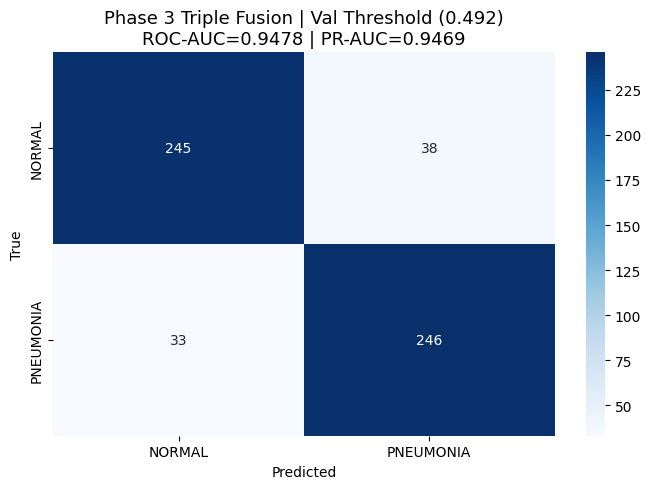

Saved confusion matrix.


In [13]:
# --- CELL 12: Confusion Matrix (val-derived threshold only) ---
fig, ax = plt.subplots(1, 1, figsize=(7, 5))
cm_arr = confusion_matrix(test_labels, preds_youden)
sns.heatmap(cm_arr, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=CLASSES, yticklabels=CLASSES)
ax.set_title(f'Phase 3 Triple Fusion | Val Threshold ({thresh_youden:.3f})\n'
             f'ROC-AUC={test_auc:.4f} | PR-AUC={test_pr_auc:.4f}', fontsize=13)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'p3_confusion_matrices.png'), bbox_inches='tight', dpi=150)
plt.show()
print('Saved confusion matrix.')


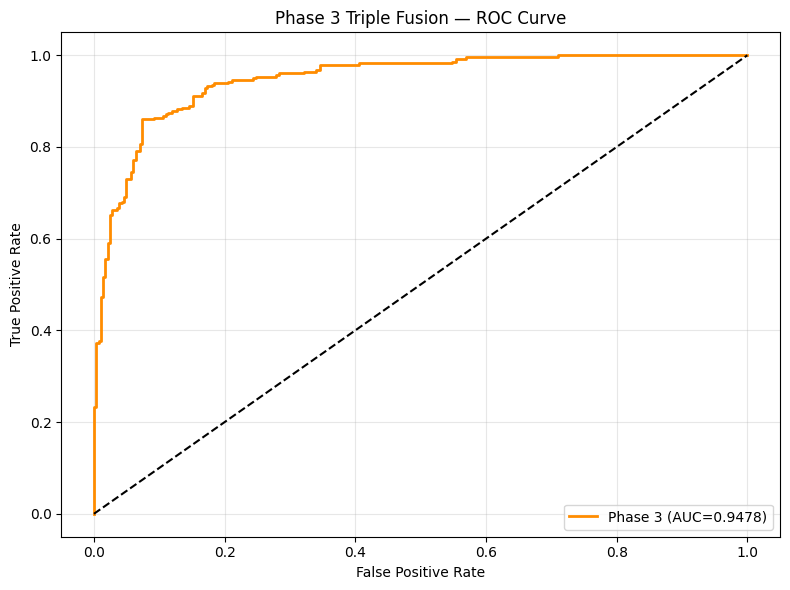

Saved ROC curve.


In [14]:
# --- CELL 13: ROC Curve ---
fpr, tpr, _ = roc_curve(test_labels, test_probs)

plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, lw=2, color='darkorange', label=f'Phase 3 (AUC={test_auc:.4f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Phase 3 Triple Fusion — ROC Curve')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'p3_roc_curve.png'), dpi=150)
plt.show()
print('Saved ROC curve.')

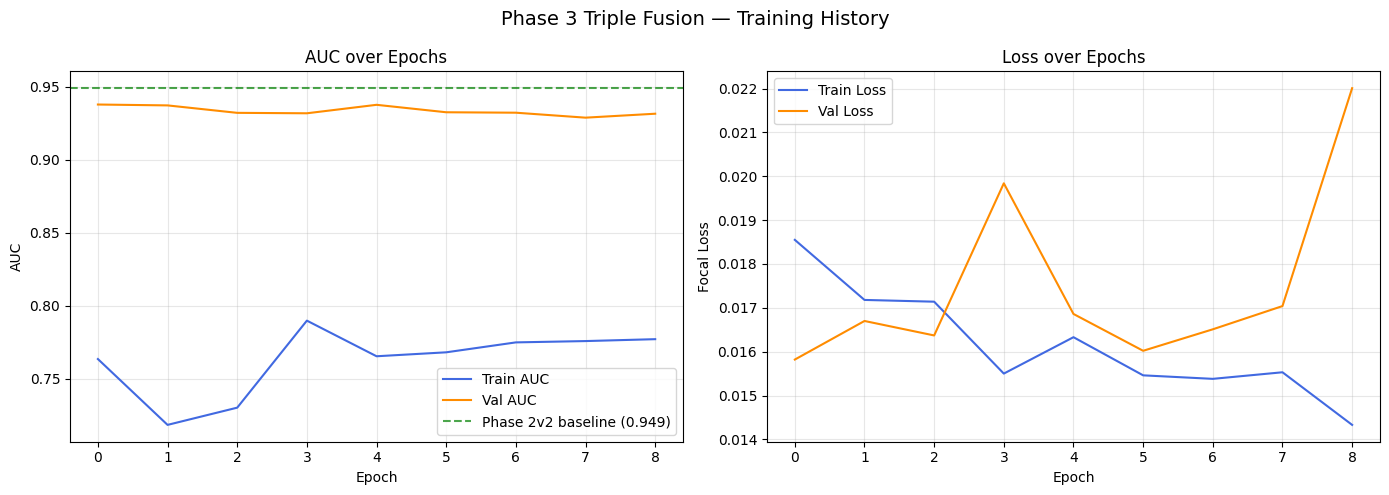

Saved training curves.


In [15]:
# --- CELL 14: Training Curves ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_auc'], label='Train AUC', color='royalblue')
axes[0].plot(history['val_auc'],   label='Val AUC',   color='darkorange')
axes[0].axhline(0.949, ls='--', color='green', alpha=0.7, label='Phase 2v2 baseline (0.949)')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('AUC')
axes[0].set_title('AUC over Epochs'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history['train_loss'], label='Train Loss', color='royalblue')
axes[1].plot(history['val_loss'],   label='Val Loss',   color='darkorange')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Focal Loss')
axes[1].set_title('Loss over Epochs'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle('Phase 3 Triple Fusion — Training History', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'p3_training_curves.png'), dpi=150)
plt.show()
print('Saved training curves.')

Computing clinical feature importances via permutation...


Baseline AUC: 0.9478


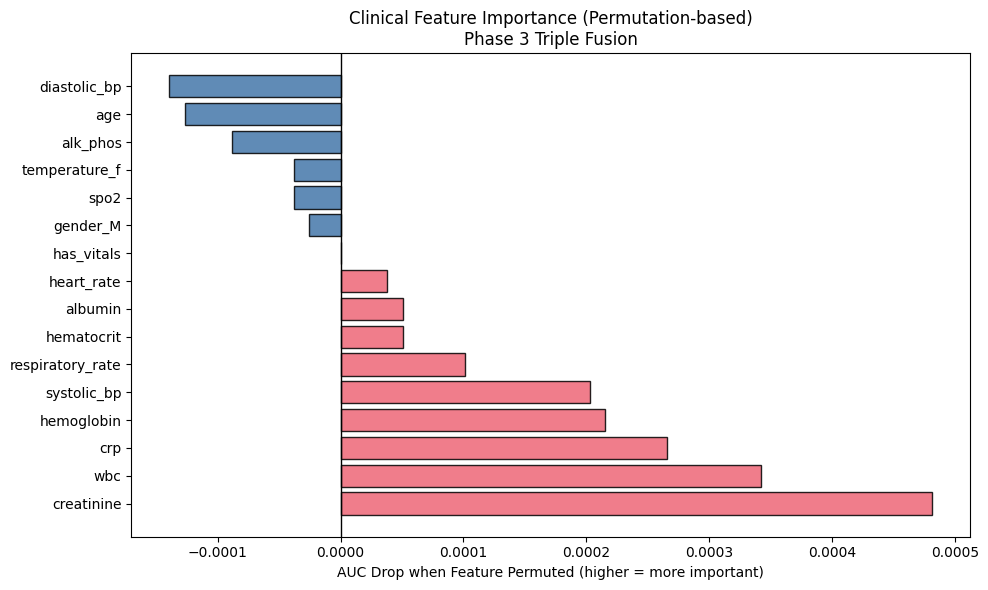


Feature Importances:
  creatinine          : +0.0005
  wbc                 : +0.0003
  crp                 : +0.0003
  hemoglobin          : +0.0002
  systolic_bp         : +0.0002
  respiratory_rate    : +0.0001
  hematocrit          : +0.0001
  albumin             : +0.0001
  heart_rate          : +0.0000
  has_vitals          : +0.0000
  gender_M            : -0.0000
  spo2                : -0.0000
  temperature_f       : -0.0000
  alk_phos            : -0.0001
  age                 : -0.0001
  diastolic_bp        : -0.0001


In [16]:
# --- CELL 15: Clinical Feature Importance (Permutation-based) ---
print('Computing clinical feature importances via permutation...')

fusion_model.eval(); image_encoder.eval(); text_encoder.eval(); meta_encoder.eval()

# Baseline AUC
_,_,baseline_auc,_,_ = eval_epoch(
    fusion_model, image_encoder, text_encoder, meta_encoder,
    test_loader, criterion_focal, DEVICE)
print(f'Baseline AUC: {baseline_auc:.4f}')

feature_importances = {}
for feat_idx, feat_name in enumerate(CLINICAL_FEATURES):
    all_probs_perm, all_labels_perm = [], []
    with torch.no_grad():
        for imgs,ids,masks,meta,labels in test_loader:
            imgs   = imgs.to(DEVICE)
            ids    = ids.to(DEVICE)
            masks  = masks.to(DEVICE)
            meta   = meta.clone().to(DEVICE)
            labels = labels.to(DEVICE)

            perm_idx = torch.randperm(meta.size(0))
            meta[:, feat_idx] = meta[perm_idx, feat_idx]

            img_f  = image_encoder(imgs)
            txt_t  = text_encoder(ids, masks)
            meta_f = meta_encoder(meta)
            logits = fusion_model(img_f, txt_t, meta_f, text_mask=masks)
            probs  = F.softmax(logits, dim=1)[:,1].cpu().numpy()
            all_probs_perm.extend(probs)
            all_labels_perm.extend(labels.cpu().tolist())

    perm_auc = roc_auc_score(all_labels_perm, all_probs_perm)
    feature_importances[feat_name] = baseline_auc - perm_auc

# Sort and plot
sorted_feats = sorted(feature_importances.items(), key=lambda x: x[1], reverse=True)
feat_names = [f[0] for f in sorted_feats]
feat_imps  = [f[1] for f in sorted_feats]

plt.figure(figsize=(10, 6))
colors_bar = ['#EE6677' if v > 0 else '#4477AA' for v in feat_imps]
plt.barh(feat_names, feat_imps, color=colors_bar, edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', lw=1)
plt.xlabel('AUC Drop when Feature Permuted (higher = more important)')
plt.title('Clinical Feature Importance (Permutation-based)\nPhase 3 Triple Fusion')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'p3_feature_importance.png'), dpi=150)
plt.show()
print('\nFeature Importances:')
for name, imp in sorted_feats:
    print(f'  {name:20s}: {imp:+.4f}')



In [17]:
# --- CELL 16: Save Results JSON & Config ---

results = {
    'phase': 3,
    'description': 'Triple Fusion: Image + Text + Clinical Metadata (Exp 5 & 6)',
    'architecture': {
        'image_encoder':  'DenseNet121+CBAM (frozen, NIH pretrained — zero MIMIC overlap)',
        'text_encoder':   'Bio_ClinicalBERT (last 2 layers unfrozen)',
        'meta_encoder':   f'MLP({N_CLINICAL_FEATURES}->128->128->{META_OUT_DIM})',
        'fusion':         'CrossAttention(img queries text, key_padding_mask) + concat meta + MLP classifier',
        'fused_dim':      IMG_FEAT_DIM + ATTN_DIM + META_OUT_DIM,
        'clinical_feats': list(CLINICAL_FEATURES),
        'is_deceased_removed': True,
        'text_fallback_removed': True,
        'key_padding_mask_used': True,
        'p2v2_weights_loaded': os.path.exists(P2V2_CKPT)
    },
    'training': {
        'n_train': len(train_df), 'n_val': len(val_df), 'n_test': len(test_df),
        'batch_size': BATCH_SIZE, 'epochs_run': len(history['val_auc']),
        'lr_fusion': LR_FUSION, 'lr_bert': LR_BERT, 'lr_meta': LR_META,
        'focal_gamma': FOCAL_GAMMA, 'mixup_alpha': MIXUP_ALPHA
    },
    'results': {
        'val_threshold':      round(thresh_youden, 4),
        'test_roc_auc':       round(test_auc, 4),
        'test_pr_auc':        round(test_pr_auc, 4),
        'test_accuracy':      round(ac_y, 4),
        'test_sensitivity':   round(s_y, 4),
        'test_specificity':   round(sp_y, 4),
        'test_f1':            round(f1_y, 4),
        'confusion_matrix': {
            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)
        },
        'n_test': len(test_labels)
    },
    'feature_importances': {k: round(v, 4) for k, v in feature_importances.items()},
    'comparison': {
        'phase1_roc_auc': 0.8080,
        'phase2_roc_auc': 0.9476,
        'phase3_roc_auc': round(test_auc, 4),
        'gain_over_p1':   round(test_auc - 0.8080, 4),
        'gain_over_p2':   round(test_auc - 0.9476, 4)
    }
}

out_path = os.path.join(SAVE_DIR, 'phase3_results.json')
with open(out_path, 'w') as f:
    json.dump(results, f, indent=2)

print('='*60)
print('PHASE 3 TRIPLE FUSION — FINAL RESULTS')
print('='*60)
print(f'Val Threshold    : {thresh_youden:.4f} (selected on validation set only)')
print(f'Test ROC-AUC     : {test_auc:.4f}')
print(f'Test PR-AUC      : {test_pr_auc:.4f}')
print(f'Accuracy         : {ac_y*100:.2f}%')
print(f'Sensitivity      : {s_y*100:.2f}%')
print(f'Specificity      : {sp_y*100:.2f}%')
print(f'Macro F1         : {f1_y:.4f}')
print(f'Confusion Matrix : TN={tn} FP={fp} FN={fn} TP={tp}')
print(f'\nvs Phase 1 (CXR only):  AUC delta = {test_auc-0.8080:+.4f}')
print(f'vs Phase 2 (CXR+Text): AUC delta = {test_auc-0.9476:+.4f}')
print(f'\nResults saved to: {out_path}')


PHASE 3 TRIPLE FUSION — FINAL RESULTS
Val Threshold    : 0.4918 (selected on validation set only)
Test ROC-AUC     : 0.9478
Test PR-AUC      : 0.9469
Accuracy         : 87.37%
Sensitivity      : 88.17%
Specificity      : 86.57%
Macro F1         : 0.8739
Confusion Matrix : TN=245 FP=38 FN=33 TP=246

vs Phase 1 (CXR only):  AUC delta = +0.1398
vs Phase 2 (CXR+Text): AUC delta = +0.0002

Results saved to: C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_3_NIH_single_split_exp5_6\phase3_results.json


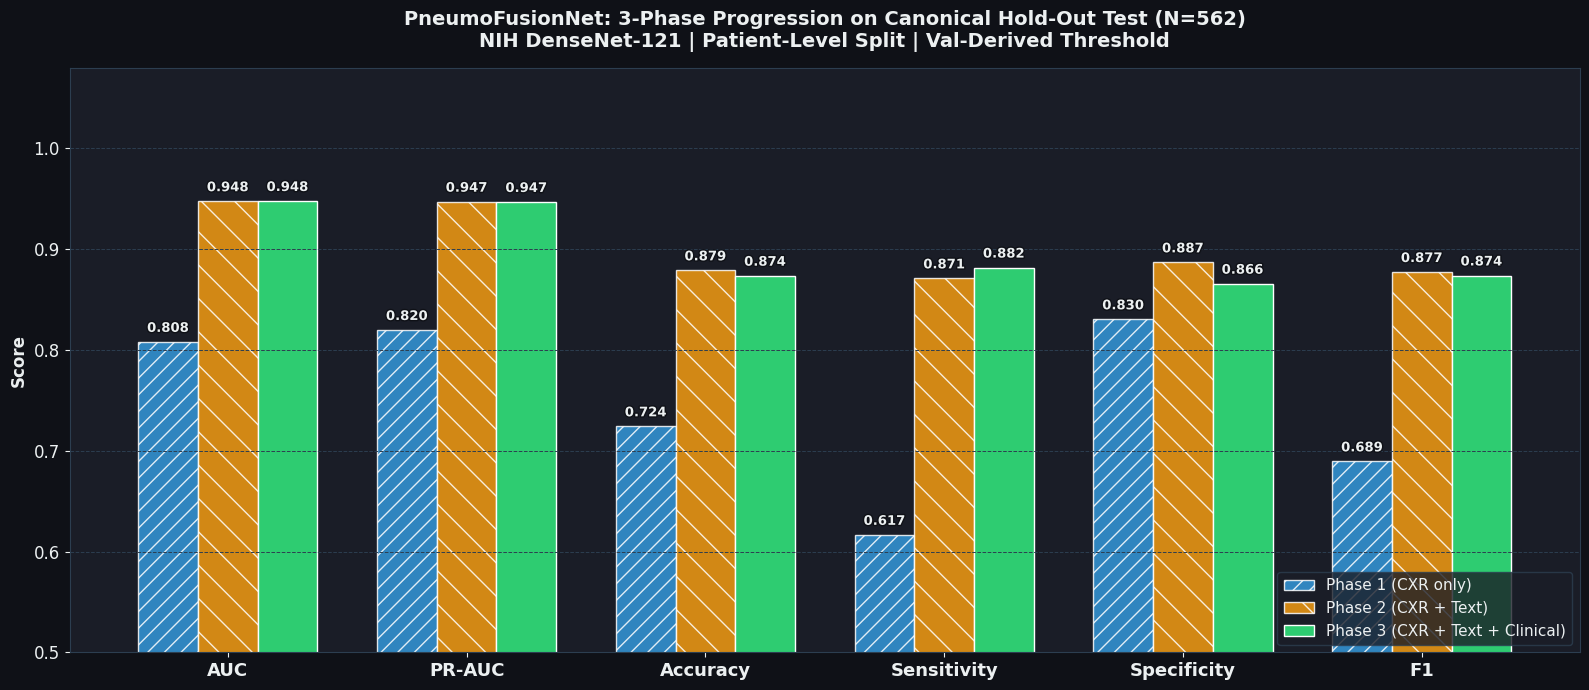


=== Direct Comparison Across All 3 Phases on Identical Test Cohort (N=562) ===
Metric           Phase 1 (CXR) Phase 2 (+Txt) Phase 3 (Triple)   Overall Gain
----------------------------------------------------------------------------
AUC                     0.8080         0.9476           0.9478 +       0.1398
PR-AUC                  0.8198         0.9471           0.9469 +       0.1271
Accuracy                0.7242         0.8790           0.8737 +       0.1495
Sensitivity             0.6165         0.8710           0.8817 +       0.2652
Specificity             0.8304         0.8869           0.8657 +       0.0353
F1                      0.6894         0.8773           0.8739 +       0.1845


In [18]:
# --- CELL 17: Full 3-Phase Pipeline Progression (Experiments 2-6) ---
import matplotlib.patches as mpatches, matplotlib.patheffects as pe
BG='#0f1117'; AX='#1a1d27'; TC='#ecf0f1'; GC='#2c3e50'

# Load Phase 1 & Phase 2 results
p1_data = json.load(open(P1_RES))
p2_data = json.load(open(P2_RES))

metrics_names = ['AUC', 'PR-AUC', 'Accuracy', 'Sensitivity', 'Specificity', 'F1']
p1_v = [
    float(p1_data['results']['test_roc_auc']),
    float(p1_data['results']['test_pr_auc']),
    float(p1_data['results']['test_accuracy']),
    float(p1_data['results']['test_sensitivity']),
    float(p1_data['results']['test_specificity']),
    float(p1_data['results']['test_f1']),
]
p2_v = [
    float(p2_data['multimodal_results']['test_roc_auc']),
    float(p2_data['multimodal_results']['test_pr_auc']),
    float(p2_data['multimodal_results']['test_accuracy']),
    float(p2_data['multimodal_results']['test_sensitivity']),
    float(p2_data['multimodal_results']['test_specificity']),
    float(p2_data['multimodal_results']['test_f1']),
]
p3_v = [
    float(test_auc),
    float(test_pr_auc),
    float(ac_y),
    float(s_y),
    float(sp_y),
    float(f1_y),
]

x = np.arange(len(metrics_names)); w = 0.25
fig, ax = plt.subplots(figsize=(16, 7))
fig.patch.set_facecolor(BG); ax.set_facecolor(AX)
ax.spines[:].set_color(GC); ax.tick_params(colors=TC, labelsize=12)

b1 = ax.bar(x - w,   p1_v, w, color='#3498db', edgecolor='white', alpha=0.85, hatch='//', label='Phase 1 (CXR only)')
b2 = ax.bar(x,       p2_v, w, color='#f39c12', edgecolor='white', alpha=0.85, hatch='\\', label='Phase 2 (CXR + Text)')
b3 = ax.bar(x + w,   p3_v, w, color='#2ecc71', edgecolor='white', alpha=1.00,              label='Phase 3 (CXR + Text + Clinical)')

for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.007,
                f'{bar.get_height():.3f}', ha='center', va='bottom',
                fontsize=9.5, fontweight='bold', color=TC,
                path_effects=[pe.withStroke(linewidth=2, foreground=BG)])

for yv in [0.6, 0.7, 0.8, 0.9, 1.0]:
    ax.axhline(yv, color=GC, lw=0.7, linestyle='--', zorder=1)
ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontsize=13, fontweight='bold', color=TC)
ax.set_ylim(0.50, 1.08)
ax.set_ylabel('Score', fontsize=12, color=TC, fontweight='bold')
ax.set_title('PneumoFusionNet: 3-Phase Progression on Canonical Hold-Out Test (N=562)\n'
             'NIH DenseNet-121 | Patient-Level Split | Val-Derived Threshold',
             fontsize=14, fontweight='bold', color=TC, pad=15)
ax.legend(fontsize=11, facecolor=AX, edgecolor=GC, labelcolor=TC, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'three_phase_comparison.png'), dpi=180, bbox_inches='tight', facecolor=BG)
plt.show()

print('\n=== Direct Comparison Across All 3 Phases on Identical Test Cohort (N=562) ===')
print(f'{"Metric":15s} {"Phase 1 (CXR)":>14s} {"Phase 2 (+Txt)":>14s} {"Phase 3 (Triple)":>16s} {"Overall Gain":>14s}')
print('-' * 76)
for m, v1, v2, v3 in zip(metrics_names, p1_v, p2_v, p3_v):
    gain = v3 - v1
    sign = '+' if gain >= 0 else ''
    print(f'{m:15s} {v1:>14.4f} {v2:>14.4f} {v3:>16.4f} {sign}{gain:>13.4f}')


In [19]:
# # --- CELL 18: Save Data Checkpoint (Resume Helper) ---
# Run this once. Next kernel restart: skip Cells 3-6 using Quick Resume. you don't re-run Cells 4-7
import pickle, os

CKPT_DATA = os.path.join(SAVE_DIR, 'phase3_data_checkpoint.pkl')
checkpoint = {
    'train_df'           : train_df,
    'val_df'             : val_df,
    'test_df'            : test_df,
    'scaler'             : scaler,
    'train_medians'      : train_medians,
    'CLINICAL_FEATURES'  : CLINICAL_FEATURES,
    'N_CLINICAL_FEATURES': N_CLINICAL_FEATURES,
}
with open(CKPT_DATA, 'wb') as f:
    pickle.dump(checkpoint, f)
print(f'Saved -> {CKPT_DATA}')
print(f'train={len(train_df)} | val={len(val_df)} | test={len(test_df)}')

Saved -> C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_3_NIH_single_split_exp5_6\phase3_data_checkpoint.pkl
train=2635 | val=566 | test=562
